In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

df = pd.read_csv('fig2_redshift_values.csv')

models = {'naive': 'Naive SFR', 'o_dependent': 'O-dependent', 'fe_dependent': 'Fe-dependent'}
model_colors = {'naive': '#808080', 'o_dependent': '#bf6360', 'fe_dependent': '#377e7f'}
panels = {'Population Total': 'Population', 'ELasTiCC': 'ELAsTiCC', 'Oracle': 'ORACLE'}

df.groupby(['panel', 'model'])[['N', 'N_R0lo', 'N_R0hi']].sum().round(1)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/vedshah/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/vedshah/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/vedshah/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loop.start()
  File "/Users

AttributeError: _ARRAY_API not found

N     N_R0lo      N_R0hi
panel            model                                          
ELasTiCC         fe_dependent    917999.0   565915.7   1509145.3
                 naive           281141.0   173314.0    462182.0
                 o_dependent     466939.0   287852.3    767624.8
Oracle           fe_dependent    790922.5   487577.3   1300237.8
                 naive           243813.4   150302.8    400817.3
                 o_dependent     402596.6   248187.4    661849.1
Population Total fe_dependent  14432797.0  8897337.2  23726809.5
                 naive          2034661.0  1254300.5   3344882.8
                 o_dependent    7033255.0  4335766.8  11562325.8

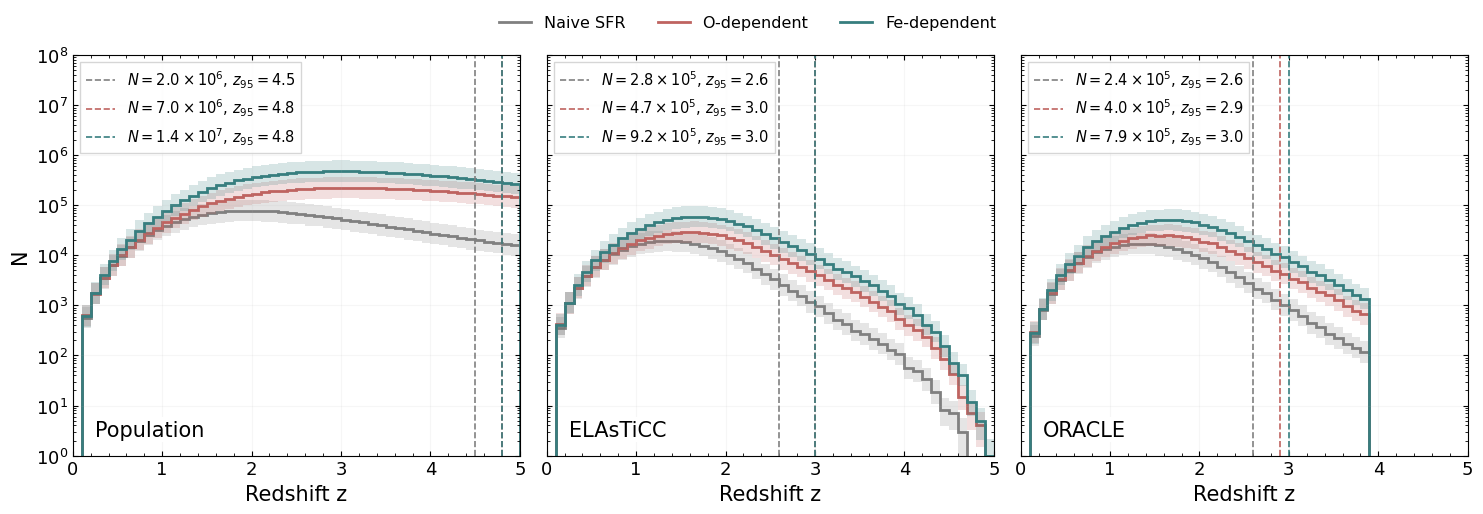

In [9]:
paper_rc = {'font.size': 13, 'axes.labelsize': 15, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
            'legend.fontsize': 11.5, 'legend.title_fontsize': 11.5,
            'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
            'xtick.minor.visible': True, 'ytick.minor.visible': True}

with plt.rc_context(paper_rc):
    fig, axs = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True, gridspec_kw={'wspace': 0.06})
    for ax, (panel, title) in zip(axs, panels.items()):
        for model, color in model_colors.items():
            d = df[(df['model'] == model) & (df['panel'] == panel)].sort_values('z_lo')
            z_edges = np.append(d['z_lo'].values, d['z_hi'].values[-1])
            N = d['N'].values
            z95 = z_edges[1:][np.searchsorted(np.cumsum(N) / N.sum(), 0.95)]
            band_lo = N - np.hypot(N - d['N_R0lo'].values, d['sqrt_N'].values)
            band_hi = N + np.hypot(d['N_R0hi'].values - N, d['sqrt_N'].values)

            ax.stairs(N, z_edges, color=color, lw=2)
            ax.stairs(band_hi, z_edges, baseline=np.clip(band_lo, 1e-3, None), fill=True, color=color, alpha=0.2, lw=0)
            e = int(np.floor(np.log10(N.sum())))
            ax.axvline(z95, color=color, ls='--', lw=1.2,
                       label=f'$N = {N.sum() / 10**e:.1f} \\times 10^{{{e}}}$, $z_{{95}} = {z95:.1f}$')

        ax.set_yscale('log')
        ax.set_ylim(1, 1e8)
        ax.set_xlim(0, 5)
        ax.set_xlabel('Redshift z')
        ax.text(0.05, 0.04, title, transform=ax.transAxes, ha='left', va='bottom', fontsize=15,
                bbox=dict(facecolor='white', edgecolor='none', pad=2))
        ax.grid(alpha=0.1)
        ax.legend(loc='upper left', fontsize=10.5, fancybox=False, facecolor='white')
    axs[0].set_ylabel('N')

    handles = [Line2D([], [], color=c, lw=2) for c in model_colors.values()]
    fig.legend(handles, list(models.values()), loc='lower center', bbox_to_anchor=(0.5, 0.9), ncol=len(handles),
               fancybox=False, facecolor='white', frameon=False)
    plt.savefig('slsn_counts_by_z.pdf', bbox_inches='tight')
    plt.show()